# BankSmart AI: term-deposit subscription prediction (Google Colab version)

This notebook reproduces the BankSmart AI model end to end: validation, leakage-aware preprocessing, model comparison,
calibration, threshold selection, test evaluation, SHAP explanations, campaign lift and prediction for new customers.

**How to use:** run the cells from top to bottom (**Runtime > Run all**). When asked, upload your `bank-full.csv` / Kaggle `train.csv`
(45,211 rows, 17 columns). Change `SCENARIO` in the settings cell to `"post_call"` to include call duration.

**Please read:** results are *offline* measurements on one historical dataset. They do not show that using the model would create
extra subscriptions, and no revenue or ROI claim is made. The data is ordered by date but this notebook (like the main project)
uses a random split, so scores are optimistic for forecasting a later campaign. The last section runs a time-ordered check.

## 1. Setup

In [1]:
%%capture
!pip install -q imbalanced-learn shap

In [2]:
import os, io, json, math, platform, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn, imblearn

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, brier_score_loss, confusion_matrix,
                             f1_score, log_loss, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve, accuracy_score, classification_report)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| imbalanced-learn", imblearn.__version__)

python 3.12.3 | pandas 2.2.3 | numpy 2.0.2 | scikit-learn 1.6.1 | imbalanced-learn 0.14.2


### Settings
* `SCENARIO`: `"pre_call"` uses only information known before dialling (call duration excluded; use this for deciding whom to call).
  `"post_call"` also uses call duration, which is only known after the call, so it is for analysis, not outreach.
* `FAST_MODE = True` runs a quicker, lighter version (less tuning, 3-fold CV). Results will differ slightly from the full run.
* `THRESHOLD_BETA = 2` favours recall (assumes a missed subscriber costs more than an extra call). No cost data exists; change it if you know your costs.

In [3]:
SCENARIO = "pre_call"      # "pre_call" or "post_call"
FAST_MODE = False          # True = quicker, lighter run
SEED = 42
THRESHOLD_BETA = 2.0
TEST_SIZE, VAL_SIZE = 0.20, 0.20
N_BOOT = 200 if FAST_MODE else 1000
CV_FOLDS = 3 if FAST_MODE else 5
N_TUNE_ITER = 3 if FAST_MODE else 5
assert SCENARIO in ("pre_call", "post_call")

NUMERIC = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
CATEGORICAL = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]
ALL_FEATURES = NUMERIC + CATEGORICAL
TARGET = "y"
LEAKAGE = {"pre_call": ["duration"], "post_call": []}
DOMAINS = {"marital": {"married", "single", "divorced"}, "education": {"primary", "secondary", "tertiary", "unknown"},
           "default": {"yes", "no"}, "housing": {"yes", "no"}, "loan": {"yes", "no"},
           "contact": {"cellular", "telephone", "unknown"},
           "month": {"jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"},
           "poutcome": {"failure", "other", "success", "unknown"}}
def scenario_features(sc): return [c for c in ALL_FEATURES if c not in LEAKAGE[sc]]
FEATURES = scenario_features(SCENARIO)
print("Scenario:", SCENARIO, "| inputs used:", len(FEATURES), "| excluded:", LEAKAGE[SCENARIO] or "none")

Scenario: pre_call | inputs used: 15 | excluded: ['duration']


## 2. Load and validate the data
Upload `bank-full.csv` (UCI) or the Kaggle `train.csv`. Source: UCI Machine Learning Repository, *Bank Marketing* (dataset 222),
CC BY 4.0, https://doi.org/10.24432/C5K306 (Moro, Rita & Cortez).

**Do not use the Kaggle `test.csv` / UCI `bank.csv` (4,521 rows):** all of its rows also appear in the full file.

In [4]:
DATA_PATH = "bank_marketing.csv"   # or set to a path on your Google Drive after mounting it

def get_data_path():
    if os.path.exists(DATA_PATH):
        return DATA_PATH
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f"Put the dataset at {DATA_PATH!r}.")
    print("Select your bank-full.csv / train.csv ...")
    uploaded = files.upload()
    if not uploaded:
        raise FileNotFoundError("No file uploaded.")
    return next(iter(uploaded))

def load_data(path):
    with open(path, "r", encoding="utf-8-sig") as fh:
        header = fh.readline()
    sep = ";" if header.count(";") > header.count(",") else ","
    df = pd.read_csv(path, sep=sep)
    missing = [c for c in ALL_FEATURES + [TARGET] if c not in df.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}. Found: {list(df.columns)}")
    for c in NUMERIC:
        if not pd.api.types.is_numeric_dtype(df[c]):
            raise ValueError(f"Column {c!r} must be numeric.")
    for c, dom in DOMAINS.items():
        bad = set(df[c].dropna().unique()) - dom
        if bad:
            raise ValueError(f"Column {c!r} has unexpected values: {sorted(bad)}")
    vals = set(df[TARGET].astype(str).str.strip().str.lower())
    if vals != {"yes", "no"}:
        raise ValueError(f"Target {TARGET!r} must contain exactly yes/no; found {sorted(vals)}")
    if len(df) == 4521:
        print("WARNING: 4,521 rows suggests the small sample file. Use the full 45,211-row file.")
    return df

df = load_data(get_data_path())
X_all = df[ALL_FEATURES].copy()
y_all = (df[TARGET].astype(str).str.strip().str.lower() == "yes").astype(int)
print(f"{len(df):,} rows | subscribed: {y_all.sum():,} ({y_all.mean():.2%}) | missing cells: {int(df.isna().sum().sum())}")
print(f"Always predicting 'no' would be {1 - y_all.mean():.1%} accurate and find no subscribers.")
df.head()

45,211 rows | subscribed: 5,289 (11.70%) | missing cells: 0
Always predicting 'no' would be 88.3% accurate and find no subscribers.


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


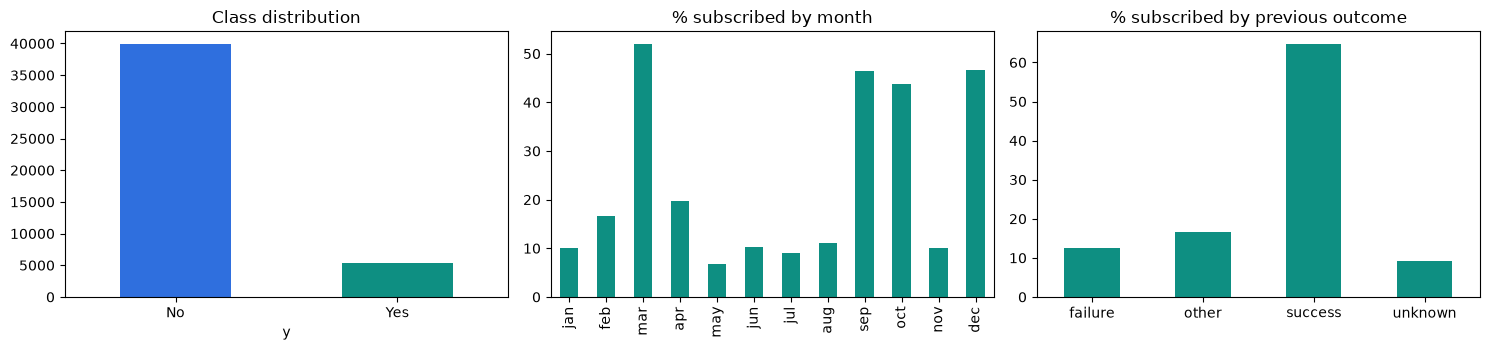

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
y_all.map({0: "No", 1: "Yes"}).value_counts().plot.bar(ax=ax[0], color=["#2F6FDE", "#0E8F82"], rot=0)
ax[0].set_title("Class distribution")
order = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
(df.assign(_y=y_all).groupby("month")["_y"].mean().reindex(order) * 100).plot.bar(ax=ax[1], color="#0E8F82")
ax[1].set_title("% subscribed by month"); ax[1].set_xlabel("")
(df.assign(_y=y_all).groupby("poutcome")["_y"].mean() * 100).plot.bar(ax=ax[2], color="#0E8F82", rot=0)
ax[2].set_title("% subscribed by previous outcome"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

## 3. Leakage-aware preprocessing and split
* The scenario decides which raw columns the model may see; for `pre_call` the pipeline itself drops `duration`.
* All learned statistics (medians, scaling, category levels) are fitted inside the pipeline, so they never see validation or test data.
* `pdays = -1` means "never contacted before": it becomes a flag, and `pdays` is set to 0 for those customers.

In [6]:
class FeatureMismatchError(ValueError):
    pass

class FeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self, scenario="pre_call", exclude=()):
        self.scenario = scenario
        self.exclude = exclude
    def _required(self):
        return [c for c in scenario_features(self.scenario) if c not in set(self.exclude)]
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        required = self._required()
        missing = [c for c in required if c not in X.columns]
        if missing:
            raise FeatureMismatchError(f"Missing required columns for scenario {self.scenario!r}: {missing}")
        out = X[required].copy()
        for c in NUMERIC:
            if c in out.columns:
                out[c] = pd.to_numeric(out[c], errors="coerce")
        out["previously_contacted"] = np.where(out["pdays"].isna(), np.nan, (out["pdays"] != -1).astype(float))
        out["pdays"] = out["pdays"].where(out["pdays"] != -1, 0)
        out["negative_balance"] = np.where(out["balance"].isna(), np.nan, (out["balance"] < 0).astype(float))
        for c in CATEGORICAL:
            if c in out.columns:
                out[c] = out[c].astype(object).where(out[c].notna(), np.nan)
        return out

def build_preprocessor(scenario, scale_numeric=True):
    req = scenario_features(scenario)
    num = [c for c in req if c in NUMERIC] + ["previously_contacted", "negative_balance"]
    cat = [c for c in req if c in CATEGORICAL]
    num_steps = [("impute", SimpleImputer(strategy="median"))] + ([("scale", StandardScaler())] if scale_numeric else [])
    ct = ColumnTransformer(
        [("num", Pipeline(num_steps), num),
         ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="missing")),
                           ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat)],
        remainder="drop", verbose_feature_names_out=False)
    ct.set_output(transform="pandas")
    return Pipeline([("features", FeatureEngineer(scenario=scenario)), ("encode", ct)])

# stratified random 60/20/20 split (same procedure and seed as the BankSmart AI project)
X_tmp, X_test, y_tmp, y_test = train_test_split(X_all, y_all, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=VAL_SIZE / (1 - TEST_SIZE),
                                                  stratify=y_tmp, random_state=SEED)
X_train, X_val, X_test = X_train[FEATURES], X_val[FEATURES], X_test[FEATURES]
print(f"train {len(X_train):,} | validation {len(X_val):,} | test {len(X_test):,} | positive rate "
      f"{y_train.mean():.4f} / {y_val.mean():.4f} / {y_test.mean():.4f}")
assert "duration" not in build_preprocessor("pre_call").fit_transform(X_train.assign(duration=0) if "duration" not in X_train else X_train).columns

train 27,126 | validation 9,042 | test 9,043 | positive rate 0.1170 / 0.1170 / 0.1170


## 4. Candidate models
Eight candidates: a plain logistic-regression **baseline**, **imbalance-aware** variants (class weights; SMOTE applied *inside* the pipeline so it only
touches training folds), a decision tree, a random forest, gradient boosting, and lightly tuned versions of the forest and boosting.

In [7]:
def make_pipe(clf, scale=True, smote=False):
    prep = build_preprocessor(SCENARIO, scale_numeric=scale)
    if smote:   # imblearn forbids nested pipelines as intermediate steps, so the steps are flattened
        return ImbPipeline(list(prep.steps) + [("smote", SMOTE(random_state=SEED)), ("clf", clf)])
    return Pipeline([("prep", prep), ("clf", clf)])

lr = lambda **kw: LogisticRegression(max_iter=2000, random_state=SEED, **kw)
candidates = {
    "logreg_baseline": make_pipe(lr()),
    "logreg_balanced": make_pipe(lr(class_weight="balanced")),
    "logreg_smote": make_pipe(lr(), smote=True),
    "decision_tree_balanced": make_pipe(DecisionTreeClassifier(max_depth=6, min_samples_leaf=50,
                                        class_weight="balanced", random_state=SEED), scale=False),
    "random_forest_balanced": make_pipe(RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                        class_weight="balanced_subsample", random_state=SEED, n_jobs=-1), scale=False),
    "hist_gradient_boosting": make_pipe(HistGradientBoostingClassifier(random_state=SEED), scale=False),
}
SEARCH = {
    "random_forest_balanced": {"clf__max_depth": [8, 12, 16, 24], "clf__min_samples_leaf": [3, 5, 10, 20],
                               "clf__max_features": ["sqrt", 0.3]},
    "hist_gradient_boosting": {"clf__learning_rate": [0.03, 0.05, 0.1], "clf__max_iter": [150, 300],
                               "clf__max_leaf_nodes": [15, 31, 63], "clf__min_samples_leaf": [20, 50, 100],
                               "clf__l2_regularization": [0.0, 1.0, 10.0], "clf__class_weight": [None, "balanced"]},
}
t0 = time.time()
for name in ("random_forest_balanced", "hist_gradient_boosting"):
    s = RandomizedSearchCV(candidates[name], SEARCH[name], n_iter=N_TUNE_ITER, scoring="average_precision",
                           cv=StratifiedKFold(3, shuffle=True, random_state=SEED), random_state=SEED, n_jobs=1, refit=False)
    s.fit(X_train, y_train)
    key = name.replace("_balanced", "") + "_tuned"
    candidates[key] = clone(candidates[name]).set_params(**s.best_params_)
    print(f"tuned {key}: inner-CV PR-AUC {s.best_score_:.3f}  params {s.best_params_}")
print(f"tuning took {time.time() - t0:.0f}s; {len(candidates)} candidates")

tuned random_forest_tuned: inner-CV PR-AUC 0.423  params {'clf__min_samples_leaf': 5, 'clf__max_features': 'sqrt', 'clf__max_depth': 16}


tuned hist_gradient_boosting_tuned: inner-CV PR-AUC 0.432  params {'clf__min_samples_leaf': 100, 'clf__max_leaf_nodes': 15, 'clf__max_iter': 300, 'clf__learning_rate': 0.05, 'clf__l2_regularization': 10.0, 'clf__class_weight': None}
tuning took 91s; 8 candidates


### Cross-validation on the training split only

In [8]:
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "recall": "recall",
           "precision": "precision", "f1": "f1", "balanced_accuracy": "balanced_accuracy"}
cv = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED)
rows = []
for name, pipe in candidates.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"model": name, **{f"{m} (mean ± sd)": f"{r['test_'+m].mean():.3f} ± {r['test_'+m].std():.3f}" for m in scoring}})
    print("cv done:", name)
cv_table = pd.DataFrame(rows)
print("\nrecall/precision/F1 here use the default 0.5 cut-off, so class-weighted models look different; AUCs do not depend on a cut-off.")
cv_table

cv done: logreg_baseline


cv done: logreg_balanced


cv done: logreg_smote


cv done: decision_tree_balanced


cv done: random_forest_balanced


cv done: hist_gradient_boosting


cv done: random_forest_tuned


cv done: hist_gradient_boosting_tuned

recall/precision/F1 here use the default 0.5 cut-off, so class-weighted models look different; AUCs do not depend on a cut-off.


,model,roc_auc (mean ± sd),pr_auc (mean ± sd),recall (mean ± sd),precision (mean ± sd),f1 (mean ± sd),balanced_accuracy (mean ± sd)
0,logreg_baseline,0.761 ± 0.008,0.399 ± 0.012,0.165 ± 0.008,0.633 ± 0.030,0.262 ± 0.013,0.576 ± 0.005
1,logreg_balanced,0.761 ± 0.007,0.396 ± 0.013,0.622 ± 0.017,0.263 ± 0.010,0.369 ± 0.012,0.695 ± 0.010
2,logreg_smote,0.757 ± 0.006,0.394 ± 0.011,0.620 ± 0.011,0.259 ± 0.005,0.365 ± 0.006,0.692 ± 0.005
3,decision_tree_balanced,0.749 ± 0.006,0.342 ± 0.007,0.539 ± 0.021,0.323 ± 0.018,0.404 ± 0.012,0.694 ± 0.006
4,random_forest_balanced,0.788 ± 0.008,0.429 ± 0.010,0.508 ± 0.012,0.426 ± 0.020,0.463 ± 0.014,0.708 ± 0.007
5,hist_gradient_boosting,0.788 ± 0.009,0.426 ± 0.013,0.215 ± 0.012,0.611 ± 0.023,0.318 ± 0.013,0.598 ± 0.005
6,random_forest_tuned,0.788 ± 0.007,0.427 ± 0.008,0.540 ± 0.011,0.399 ± 0.016,0.459 ± 0.011,0.716 ± 0.006
7,hist_gradient_boosting_tuned,0.790 ± 0.010,0.433 ± 0.006,0.214 ± 0.017,0.606 ± 0.018,0.316 ± 0.017,0.598 ± 0.007


## 5. Evaluation helpers
Metrics for the positive (subscribed) class. **Accuracy is not the headline** because only about 12% of customers subscribe.

In [9]:
def best_threshold_fbeta(y, p, beta=THRESHOLD_BETA):
    prec, rec, thr = precision_recall_curve(y, p)
    prec, rec = prec[:-1], rec[:-1]
    b2 = beta ** 2
    with np.errstate(divide="ignore", invalid="ignore"):
        f = np.nan_to_num((1 + b2) * prec * rec / (b2 * prec + rec))
    i = int(np.argmax(f))
    return float(thr[i]), float(f[i])

def ece(y, p, n_bins=10):
    y, p = np.asarray(y), np.asarray(p)
    b = np.minimum((p * n_bins).astype(int), n_bins - 1)
    return float(sum((b == k).mean() * abs(y[b == k].mean() - p[b == k].mean()) for k in range(n_bins) if (b == k).any()))

def metrics_at(y, p, thr):
    y, p = np.asarray(y), np.asarray(p)
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"threshold": thr, "roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p),
            "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred, zero_division=0),
            "f1": f1_score(y, pred, zero_division=0), "balanced_accuracy": balanced_accuracy_score(y, pred),
            "accuracy": accuracy_score(y, pred), "brier": brier_score_loss(y, p),
            "log_loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)), "ece": ece(y, p),
            "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn), "n_flagged": int(pred.sum())}

proba = lambda m, X: m.predict_proba(X)[:, 1]

## 6. Compare all models on the same validation and test splits
Each model gets its own decision threshold, chosen **on validation data** by maximising F-beta. **The model is selected on validation PR-AUC only.**
Test results are shown for transparency and are never used for selection.

In [10]:
fitted, rows = {}, []
for name, pipe in candidates.items():
    m = clone(pipe).fit(X_train, y_train)
    fitted[name] = m
    pv, pt = proba(m, X_val), proba(m, X_test)
    thr, _ = best_threshold_fbeta(y_val, pv)
    for split, yy, pp in (("validation", y_val, pv), ("test", y_test, pt)):
        rows.append({"model": name, "split": split, **metrics_at(yy, pp, thr)})
comparison = pd.DataFrame(rows)
show = ["model", "pr_auc", "roc_auc", "precision", "recall", "f1", "balanced_accuracy", "threshold", "n_flagged"]
print("VALIDATION (used for selection)")
display(comparison[comparison.split == "validation"][show].sort_values("pr_auc", ascending=False).round(4).reset_index(drop=True))
print("TEST (reporting only)")
display(comparison[comparison.split == "test"][show].sort_values("pr_auc", ascending=False).round(4).reset_index(drop=True))
val_tab = comparison[comparison.split == "validation"].set_index("model")
selected = val_tab["pr_auc"].idxmax()
print(f"\nSelected by highest validation PR-AUC: {selected} ({val_tab.loc[selected, 'pr_auc']:.4f})")
top = val_tab["pr_auc"].sort_values(ascending=False)
print(f"Gap between 1st and 3rd on validation PR-AUC: {top.iloc[0] - top.iloc[2]:.3f} -- compare with the CV standard deviations above; the ordering among the top models is tentative.")

VALIDATION (used for selection)


,model,pr_auc,roc_auc,precision,recall,f1,balanced_accuracy,threshold,n_flagged
0,hist_gradient_boosting,0.4809,0.8038,0.3362,0.6664,0.4469,0.7460,0.1126,2097
1,hist_gradient_boosting_tuned,0.4735,0.8033,0.3112,0.6881,0.4286,0.7432,0.1057,2339
2,random_forest_balanced,0.4574,0.7993,0.3854,0.6229,0.4762,0.7456,0.4221,1710
3,random_forest_tuned,0.4573,0.8012,0.3689,0.6210,0.4628,0.7401,0.4596,1781
4,logreg_baseline,0.4135,0.7701,0.3012,0.5936,0.3996,0.7055,0.1322,2085
5,logreg_smote,0.4097,0.7677,0.2583,0.6512,0.3699,0.7017,0.4906,2667
6,logreg_balanced,0.4093,0.7708,0.2615,0.6456,0.3722,0.7020,0.4939,2612
7,decision_tree_balanced,0.3557,0.7561,0.2723,0.6153,0.3775,0.6987,0.4592,2391


TEST (reporting only)


,model,pr_auc,roc_auc,precision,recall,f1,balanced_accuracy,threshold,n_flagged
0,hist_gradient_boosting_tuned,0.4566,0.8021,0.3053,0.6767,0.4208,0.7364,0.1057,2345
1,hist_gradient_boosting,0.4553,0.8009,0.3250,0.6484,0.4329,0.7350,0.1126,2111
2,random_forest_balanced,0.4499,0.8005,0.3762,0.6030,0.4633,0.7353,0.4221,1696
3,random_forest_tuned,0.4445,0.7996,0.3553,0.6106,0.4492,0.7319,0.4596,1818
4,logreg_baseline,0.4106,0.7708,0.3020,0.5898,0.3995,0.7046,0.1322,2066
5,logreg_balanced,0.4093,0.7709,0.2604,0.6399,0.3701,0.6995,0.4939,2600
6,logreg_smote,0.4092,0.7666,0.2528,0.6437,0.3630,0.6958,0.4906,2694
7,decision_tree_balanced,0.3438,0.7521,0.2616,0.6257,0.3689,0.6958,0.4592,2531



Selected by highest validation PR-AUC: hist_gradient_boosting (0.4809)
Gap between 1st and 3rd on validation PR-AUC: 0.023 -- compare with the CV standard deviations above; the ordering among the top models is tentative.


## 7. Probability calibration and decision threshold (validation data only)

In [11]:
base = fitted[selected]
cal_models = {"none": base}
for method in ("sigmoid", "isotonic"):
    cal_models[method] = CalibratedClassifierCV(estimator=clone(candidates[selected]), method=method, cv=5).fit(X_train, y_train)
cal_rows = []
for k, m in cal_models.items():
    mm = metrics_at(y_val, proba(m, X_val), 0.5)
    cal_rows.append({"method": k, "brier": mm["brier"], "log_loss": mm["log_loss"], "ece": mm["ece"], "pr_auc": mm["pr_auc"]})
cal_table = pd.DataFrame(cal_rows)
best_cal = cal_table.loc[cal_table.brier.idxmin(), "method"]
final = cal_models[best_cal]
display(cal_table.round(4))
pv = proba(final, X_val)
THRESHOLD, fb = best_threshold_fbeta(y_val, pv)
print(f"Calibration chosen by validation Brier score: {best_cal}")
print(f"Decision threshold (maximises F{THRESHOLD_BETA:g} on validation): {THRESHOLD:.3f}")

,method,brier,log_loss,ece,pr_auc
0,none,0.0794,0.2793,0.0077,0.4809
1,sigmoid,0.0796,0.2788,0.0104,0.4765
2,isotonic,0.0796,0.2784,0.0080,0.4747


Calibration chosen by validation Brier score: none
Decision threshold (maximises F2 on validation): 0.113


## 8. Final evaluation on the held-out test set
Scored once, after every choice above. Confidence intervals come from a bootstrap of the test set (they reflect test-sample variation only).

In [12]:
pt = proba(final, X_test)
test_m = metrics_at(y_test, pt, THRESHOLD)

rng = np.random.default_rng(SEED)
yt = y_test.to_numpy(); n = len(yt)
boot = {k: [] for k in ("roc_auc", "pr_auc", "precision", "recall", "f1")}
for _ in range(N_BOOT):
    i = rng.integers(0, n, n)
    yb, pb = yt[i], pt[i]
    if yb.min() == yb.max(): continue
    pr_ = (pb >= THRESHOLD).astype(int)
    boot["roc_auc"].append(roc_auc_score(yb, pb)); boot["pr_auc"].append(average_precision_score(yb, pb))
    boot["precision"].append(precision_score(yb, pr_, zero_division=0)); boot["recall"].append(recall_score(yb, pr_, zero_division=0))
    boot["f1"].append(f1_score(yb, pr_, zero_division=0))
summary = pd.DataFrame([{"metric": k, "value": test_m[k], "95% CI low": np.percentile(v, 2.5), "95% CI high": np.percentile(v, 97.5)}
                        for k, v in boot.items()])
print(f"FINAL MODEL: {selected} | calibration: {best_cal} | threshold {THRESHOLD:.3f} | scenario {SCENARIO}")
display(summary.round(3))
print(f"accuracy {test_m['accuracy']:.3f} (always-'no' baseline: {1 - y_test.mean():.3f}) | balanced accuracy {test_m['balanced_accuracy']:.3f} "
      f"| Brier {test_m['brier']:.4f} | ECE {test_m['ece']:.4f}")
print(f"TP {test_m['tp']:,} | FP {test_m['fp']:,} (wasted calls) | FN {test_m['fn']:,} (missed subscribers) | TN {test_m['tn']:,}")
print(classification_report(y_test, (pt >= THRESHOLD).astype(int), target_names=["not subscribed", "subscribed"], digits=3))

FINAL MODEL: hist_gradient_boosting | calibration: none | threshold 0.113 | scenario pre_call


,metric,value,95% CI low,95% CI high
0,roc_auc,0.801,0.785,0.816
1,pr_auc,0.455,0.424,0.489
2,precision,0.325,0.305,0.345
3,recall,0.648,0.619,0.677
4,f1,0.433,0.412,0.454


accuracy 0.801 (always-'no' baseline: 0.883) | balanced accuracy 0.735 | Brier 0.0810 | ECE 0.0092
TP 686 | FP 1,425 (wasted calls) | FN 372 (missed subscribers) | TN 6,560
                precision    recall  f1-score   support

not subscribed      0.946     0.822     0.880      7985
    subscribed      0.325     0.648     0.433      1058

      accuracy                          0.801      9043
     macro avg      0.636     0.735     0.656      9043
  weighted avg      0.874     0.801     0.827      9043



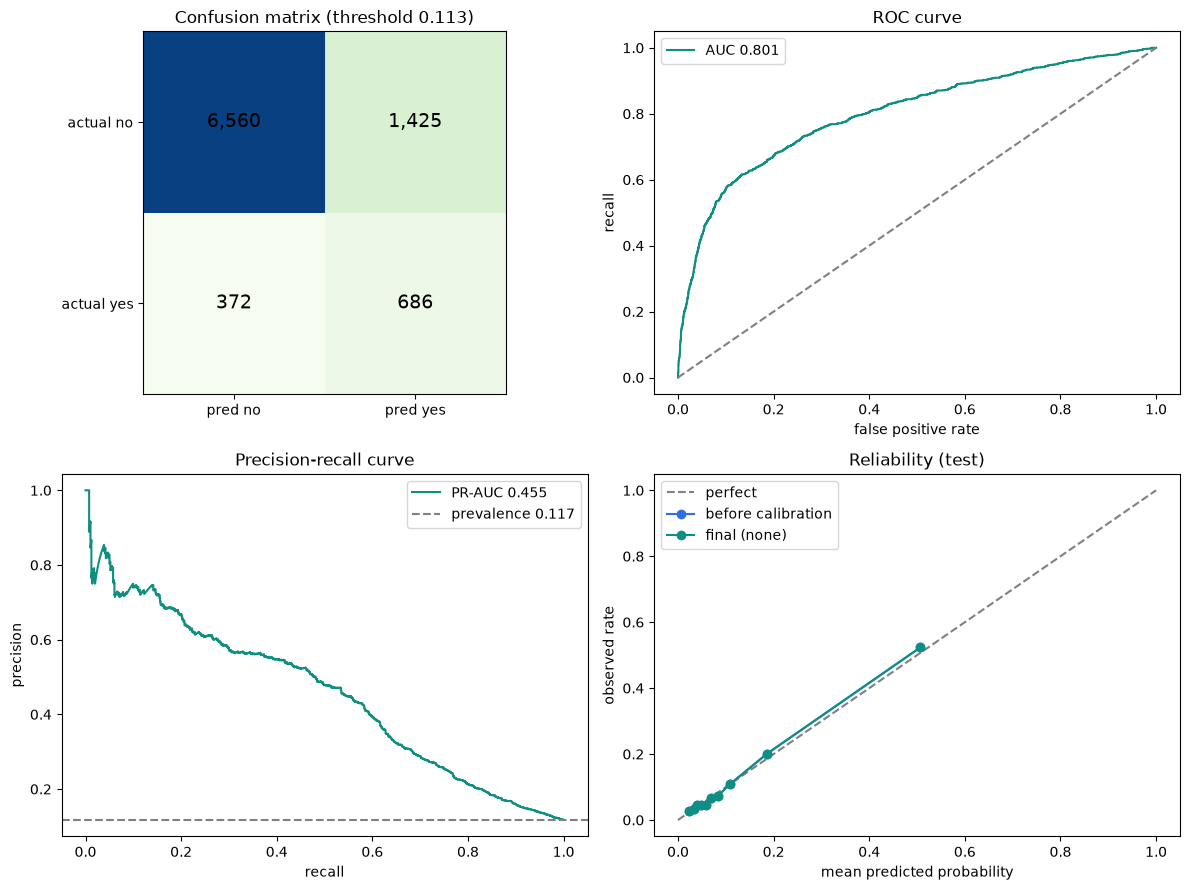

In [13]:
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
cm = np.array([[test_m["tn"], test_m["fp"]], [test_m["fn"], test_m["tp"]]])
ax[0, 0].imshow(cm, cmap="GnBu")
for (i, j), v in np.ndenumerate(cm): ax[0, 0].text(j, i, f"{v:,}", ha="center", va="center", fontsize=14)
ax[0, 0].set_xticks([0, 1], ["pred no", "pred yes"]); ax[0, 0].set_yticks([0, 1], ["actual no", "actual yes"])
ax[0, 0].set_title(f"Confusion matrix (threshold {THRESHOLD:.3f})")
fpr, tpr, _ = roc_curve(y_test, pt)
ax[0, 1].plot(fpr, tpr, color="#0E8F82", label=f"AUC {test_m['roc_auc']:.3f}"); ax[0, 1].plot([0, 1], [0, 1], "--", color="grey")
ax[0, 1].set_title("ROC curve"); ax[0, 1].set_xlabel("false positive rate"); ax[0, 1].set_ylabel("recall"); ax[0, 1].legend()
pr_, rc_, _ = precision_recall_curve(y_test, pt)
ax[1, 0].plot(rc_, pr_, color="#0E8F82", label=f"PR-AUC {test_m['pr_auc']:.3f}")
ax[1, 0].axhline(y_test.mean(), ls="--", color="grey", label=f"prevalence {y_test.mean():.3f}")
ax[1, 0].set_title("Precision-recall curve"); ax[1, 0].set_xlabel("recall"); ax[1, 0].set_ylabel("precision"); ax[1, 0].legend()
fr, mp = calibration_curve(y_test, pt, n_bins=10, strategy="quantile")
fr0, mp0 = calibration_curve(y_test, proba(base, X_test), n_bins=10, strategy="quantile")
ax[1, 1].plot([0, 1], [0, 1], "--", color="grey", label="perfect")
ax[1, 1].plot(mp0, fr0, "o-", color="#2F6FDE", label="before calibration"); ax[1, 1].plot(mp, fr, "o-", color="#0E8F82", label=f"final ({best_cal})")
ax[1, 1].set_title("Reliability (test)"); ax[1, 1].set_xlabel("mean predicted probability"); ax[1, 1].set_ylabel("observed rate"); ax[1, 1].legend()
plt.tight_layout(); plt.show()

### Threshold tuning: how precision, recall and the number of flagged customers change

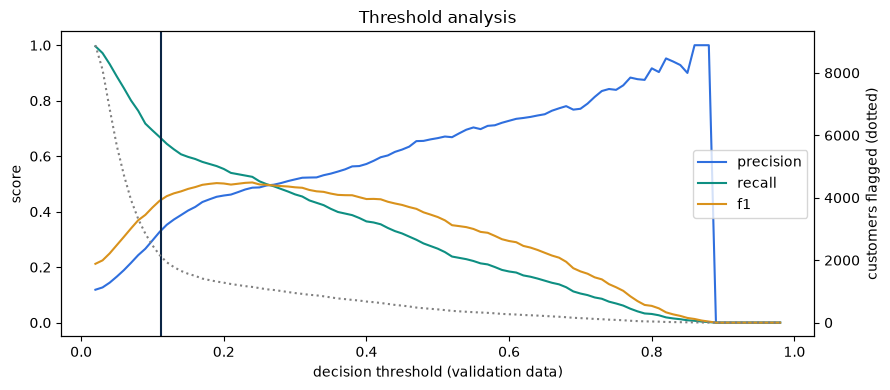

,threshold,precision,recall,f1,flagged
3,0.05,0.166,0.888,0.279,5663
8,0.10,0.296,0.693,0.415,2474
13,0.15,0.404,0.597,0.482,1564
18,0.20,0.458,0.554,0.501,1279
28,0.30,0.516,0.462,0.488,947
48,0.50,0.665,0.267,0.381,424


In [14]:
ths = np.round(np.arange(0.02, 0.99, 0.01), 2)
sweep = pd.DataFrame([{"threshold": t, "precision": precision_score(y_val, (pv >= t).astype(int), zero_division=0),
                       "recall": recall_score(y_val, (pv >= t).astype(int), zero_division=0),
                       "f1": f1_score(y_val, (pv >= t).astype(int), zero_division=0),
                       "flagged": int((pv >= t).sum())} for t in ths])
fig, a = plt.subplots(figsize=(9, 4))
for c, col in (("precision", "#2F6FDE"), ("recall", "#0E8F82"), ("f1", "#D9921C")): a.plot(sweep.threshold, sweep[c], label=c, color=col)
a.axvline(THRESHOLD, color="#0B2545"); a.set_xlabel("decision threshold (validation data)"); a.set_ylabel("score"); a.legend(loc="center right")
b = a.twinx(); b.plot(sweep.threshold, sweep.flagged, ":", color="grey"); b.set_ylabel("customers flagged (dotted)")
plt.title("Threshold analysis"); plt.tight_layout(); plt.show()
sweep[sweep.threshold.isin([0.05, 0.10, 0.15, 0.20, 0.30, 0.50])].round(3)

## 9. Campaign prioritisation (offline, historical test set)
Rank customers by predicted probability and contact the top share. **This only describes how well the model ranked past customers.** It does not show that
contacting them would *cause* extra subscriptions, and it supports no revenue or ROI claim; that would need cost data and a randomised experiment.

,outreach,customers selected,subscribers found,precision,recall,lift,found by random selection
0,10%,905,474,0.524,0.448,4.477,105.882
1,20%,1809,656,0.363,0.620,3.100,211.647
2,30%,2713,754,0.278,0.713,2.375,317.412


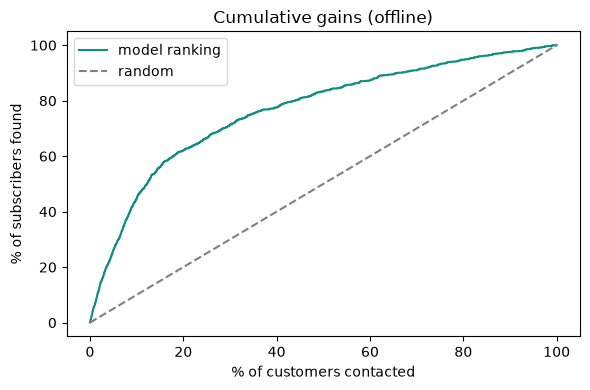

In [15]:
order_ = np.argsort(-pt, kind="mergesort")
ranked_y = y_test.to_numpy()[order_]
prev = y_test.mean(); total_pos = int(y_test.sum())
rows = []
for q in (0.10, 0.20, 0.30):
    k = int(math.ceil(q * len(ranked_y))); found = int(ranked_y[:k].sum())
    rows.append({"outreach": f"{q:.0%}", "customers selected": k, "subscribers found": found, "precision": found / k,
                 "recall": found / total_pos, "lift": (found / k) / prev, "found by random selection": k * prev})
campaign = pd.DataFrame(rows)
display(campaign.round(3))
cum = np.cumsum(ranked_y)
frac = np.arange(1, len(ranked_y) + 1) / len(ranked_y)
plt.figure(figsize=(6, 4)); plt.plot(frac * 100, cum / total_pos * 100, color="#0E8F82", label="model ranking")
plt.plot([0, 100], [0, 100], "--", color="grey", label="random"); plt.xlabel("% of customers contacted"); plt.ylabel("% of subscribers found")
plt.title("Cumulative gains (offline)"); plt.legend(); plt.tight_layout(); plt.show()

## 10. Explainable AI (SHAP)
SHAP shows how the **model** used each input for a prediction. It reflects associations in historical data. It does **not** show that changing a customer's
attribute would change their behaviour. Explanations are computed on the uncalibrated base model with its exact preprocessing; if SHAP fails the notebook falls back to
permutation importance.

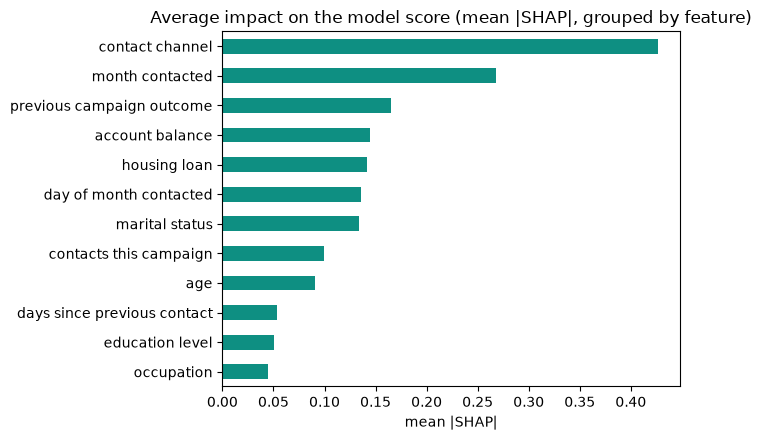

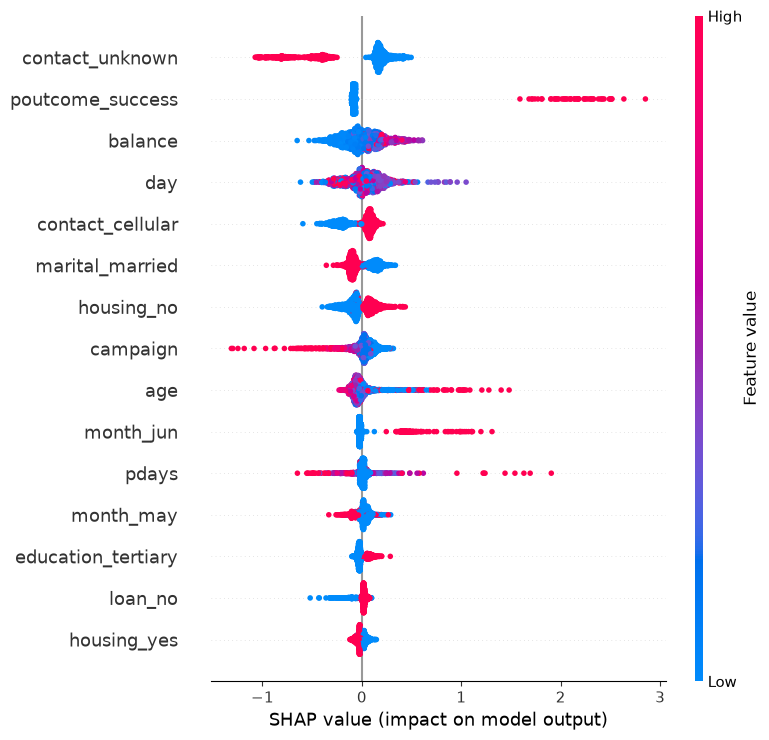

In [16]:
FEATURE_LABELS = {"age": "age", "job": "occupation", "marital": "marital status", "education": "education level", "default": "credit in default",
                  "balance": "account balance", "housing": "housing loan", "loan": "personal loan", "contact": "contact channel",
                  "day": "day of month contacted", "month": "month contacted", "duration": "call duration (s)", "campaign": "contacts this campaign",
                  "pdays": "days since previous contact", "previous": "earlier contacts", "poutcome": "previous campaign outcome",
                  "previously_contacted": "previously contacted (flag)", "negative_balance": "negative balance (flag)"}
label = lambda f: FEATURE_LABELS.get(f, f)
def feature_group(col):
    for c in CATEGORICAL:
        if col.startswith(c + "_"): return c
    return col

if "prep" in base.named_steps:
    prep_pipe = base.named_steps["prep"]
else:
    prep_pipe = Pipeline([(n, s) for n, s in base.steps if n in ("features", "encode")])
clf = base.steps[-1][1]
shap_ok = False
try:
    import shap
    sample = X_val.sample(min(1500, len(X_val)), random_state=SEED)
    Xt = prep_pipe.transform(sample)
    try:
        explainer = shap.TreeExplainer(clf); sv = explainer.shap_values(Xt)
    except Exception:
        explainer = shap.LinearExplainer(clf, Xt.head(200)); sv = explainer.shap_values(Xt)
    if isinstance(sv, list): sv = sv[-1]
    sv = np.asarray(sv)
    if sv.ndim == 3: sv = sv[:, :, -1]
    base_value = float(np.atleast_1d(np.asarray(explainer.expected_value, dtype=float))[-1])
    signed = pd.DataFrame(sv, columns=Xt.columns).T.groupby(feature_group).sum().T
    gi = signed.abs().mean().sort_values(ascending=False)
    gi.head(12).iloc[::-1].rename(index=label).plot.barh(color="#0E8F82", figsize=(7, 4.5))
    plt.title("Average impact on the model score (mean |SHAP|, grouped by feature)"); plt.xlabel("mean |SHAP|"); plt.tight_layout(); plt.show()
    shap.summary_plot(sv, Xt, max_display=15, show=True)
    shap_ok = True
except Exception as exc:
    print(f"SHAP unavailable ({type(exc).__name__}: {exc}). Falling back to permutation importance.")
    pi = permutation_importance(base, X_val.sample(min(3000, len(X_val)), random_state=SEED), y_val.loc[X_val.sample(min(3000, len(X_val)), random_state=SEED).index],
                                scoring="average_precision", n_repeats=3, random_state=SEED, n_jobs=1)
    pd.Series(pi.importances_mean, index=X_val.columns).sort_values().tail(12).rename(index=label).plot.barh(color="#2F6FDE", figsize=(7, 4.5))
    plt.title("Permutation importance (drop in PR-AUC)"); plt.tight_layout(); plt.show()

Estimated subscription probability: 71.8%  (above the threshold 11.3%)


,age,balance,day,campaign,pdays,previous,job,marital,education,default,housing,loan,contact,month,poutcome
44884,40,3840,24,2,409,2,management,single,tertiary,no,yes,no,cellular,sep,success


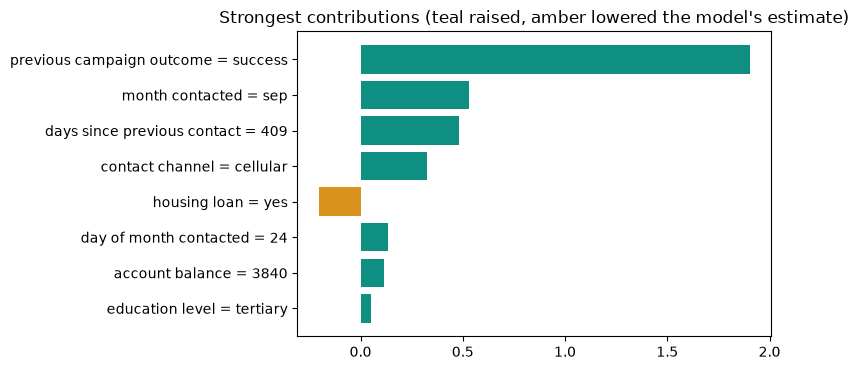

- Previous campaign outcome = success raised the model's estimate.
- Month contacted = sep raised the model's estimate.
- Days since previous contact = 409 raised the model's estimate.
These describe how the model used the inputs, not causes: changing an attribute would not necessarily change the customer's behaviour.


In [17]:
# Individual explanation: pick any validation customer by position
idx = 0
row = X_val.iloc[[idx]]
p_row = float(proba(final, row)[0])
print(f"Estimated subscription probability: {p_row:.1%}  ({'above' if p_row >= THRESHOLD else 'below'} the threshold {THRESHOLD:.1%})")
display(row)
if shap_ok:
    Xt_row = prep_pipe.transform(row)
    sv_row = np.asarray(explainer.shap_values(Xt_row))
    if isinstance(explainer.shap_values(Xt_row), list): sv_row = np.asarray(explainer.shap_values(Xt_row)[-1])
    if sv_row.ndim == 3: sv_row = sv_row[:, :, -1]
    contrib = pd.Series(sv_row[0], index=Xt_row.columns).groupby(feature_group).sum()
    contrib = contrib.reindex(contrib.abs().sort_values(ascending=False).index)
    top = contrib.head(8).iloc[::-1]
    names = [f"{label(f)} = {row.iloc[0][f] if f in row.columns else Xt_row.iloc[0][f]}" for f in top.index]
    plt.figure(figsize=(8, 3.8)); plt.barh(names, top.values, color=["#0E8F82" if v > 0 else "#D9921C" for v in top.values])
    plt.title("Strongest contributions (teal raised, amber lowered the model's estimate)"); plt.tight_layout(); plt.show()
    for f, v in contrib.head(3).items():
        print(f"- {label(f).capitalize()} = {row.iloc[0][f] if f in row.columns else Xt_row.iloc[0][f]} {'raised' if v > 0 else 'lowered'} the model's estimate.")
    print("These describe how the model used the inputs, not causes: changing an attribute would not necessarily change the customer's behaviour.")

## 11. Predict for new customers (single and batch)
Input checks mirror the app: required columns must exist with exact names (never guessed); non-numeric or out-of-range values make a row **invalid** (no prediction);
missing cells and unseen categories are scored but **flagged**. `duration` is ignored in the pre-call scenario.

In [18]:
RANGES = {"age": (18, 100), "balance": (-100_000, 1_000_000), "day": (1, 31), "duration": (0, 10_000),
          "campaign": (1, 100), "pdays": (-1, 1_000), "previous": (0, 100)}
known = {c: set(map(str, v)) for c, v in zip([c for c in FEATURES if c in CATEGORICAL],
         base.named_steps["prep"].named_steps["encode"].named_transformers_["cat"].named_steps["onehot"].categories_)} \
        if "prep" in base.named_steps else {}

def predict_customers(customers: pd.DataFrame, threshold=None):
    thr = THRESHOLD if threshold is None else float(threshold)
    if not 0 <= thr <= 1: raise ValueError("threshold must be between 0 and 1")
    missing = [c for c in FEATURES if c not in customers.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}. Required: {FEATURES}")
    X = customers[FEATURES].copy()
    notes = pd.Series([""] * len(X), index=X.index); invalid = pd.Series(False, index=X.index)
    def add(mask, text):
        for i in X.index[mask]: notes[i] = (notes[i] + "; " if notes[i] else "") + text
    for c in [c for c in FEATURES if c in NUMERIC]:
        num = pd.to_numeric(X[c], errors="coerce")
        bad = X[c].notna() & num.isna(); lo, hi = RANGES[c]; oor = num.notna() & ((num < lo) | (num > hi))
        add(bad, f"INVALID non-numeric {c}"); add(oor, f"INVALID {c} outside [{lo}, {hi}]")
        add(num.isna() & ~bad, f"{c} missing (training median used)"); invalid |= bad | oor; X[c] = num
    for c in [c for c in FEATURES if c in CATEGORICAL]:
        v = X[c].astype(object); v = v.where(v.notna() & (v.astype(str).str.strip() != ""), np.nan); X[c] = v
        add(v.isna(), f"{c} missing (own 'missing' level)")
        if c in known: add(v.notna() & ~v.astype(str).isin(known[c]), f"unseen category in {c}")
    out = pd.DataFrame(index=X.index); out["probability"] = np.nan
    ok = ~invalid
    if ok.any(): out.loc[ok, "probability"] = proba(final, X.loc[ok])
    out["predicted_class"] = np.where(out.probability.isna(), np.nan, (out.probability >= thr).astype(float))
    out["status"] = np.where(invalid, "invalid", np.where(notes != "", "warning", "ok")); out["data_quality_note"] = notes
    return out

# Example: 5 validation customers
display(predict_customers(X_val.head(5)).round(3))

,probability,predicted_class,status,data_quality_note
44884,0.718,1.0,ok,
22611,0.058,0.0,ok,
35231,0.070,0.0,ok,
26659,0.080,0.0,ok,
36918,0.039,0.0,ok,


In [19]:
# Example: one new customer (edit the values). Include 'duration' only if SCENARIO = "post_call".
new_customer = {"age": 41, "job": "management", "marital": "married", "education": "tertiary", "default": "no", "balance": 1200,
                "housing": "no", "loan": "no", "contact": "cellular", "day": 12, "month": "aug", "campaign": 1,
                "pdays": -1, "previous": 0, "poutcome": "unknown"}
if SCENARIO == "post_call": new_customer["duration"] = 240
res = predict_customers(pd.DataFrame([new_customer])).iloc[0]
print(f"Estimated probability of subscribing: {res.probability:.1%} | class: {'likely subscriber' if res.predicted_class == 1 else 'not flagged'} "
      f"| status: {res.status} {res.data_quality_note}")
print("This is a probabilistic estimate from a statistical model, not a guarantee.")

Estimated probability of subscribing: 21.9% | class: likely subscriber | status: ok 
This is a probabilistic estimate from a statistical model, not a guarantee.


In [20]:
# Batch prediction from your own CSV (optional): run this cell, upload a file with the required columns, then download the results.
try:
    from google.colab import files
    up = files.upload()
    if up:
        name = next(iter(up)); batch = pd.read_csv(io.BytesIO(up[name]), sep=None, engine="python")
        res = predict_customers(batch)
        out = batch.join(res)
        print(res.status.value_counts().to_dict())
        out.to_csv("banksmart_predictions.csv", index=False); files.download("banksmart_predictions.csv")
except ImportError:
    print("Batch upload works inside Google Colab. Call predict_customers(your_dataframe) elsewhere.")

Batch upload works inside Google Colab. Call predict_customers(your_dataframe) elsewhere.


## 12. Save the model and results
Saves the final calibrated pipeline, the metadata (seed, versions, threshold, metrics) and the comparison tables. Reload later with `joblib.load`
(use the same scikit-learn version).

In [21]:
os.makedirs("banksmart_output", exist_ok=True)
joblib.dump(final, f"banksmart_output/model_{SCENARIO}.joblib")
meta = {"scenario": SCENARIO, "selected_model": selected, "calibration": best_cal, "threshold": THRESHOLD,
        "threshold_objective": f"maximise F{THRESHOLD_BETA:g} on validation data", "input_features": FEATURES,
        "excluded_features": LEAKAGE[SCENARIO], "seed": SEED, "fast_mode": FAST_MODE,
        "test_metrics": {k: float(v) for k, v in test_m.items()},
        "environment": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                        "scikit-learn": sklearn.__version__, "imbalanced-learn": imblearn.__version__}}
json.dump(meta, open(f"banksmart_output/metadata_{SCENARIO}.json", "w"), indent=2)
comparison.to_csv(f"banksmart_output/model_comparison_{SCENARIO}.csv", index=False)
campaign.to_csv(f"banksmart_output/campaign_{SCENARIO}.csv", index=False)
print(os.listdir("banksmart_output"))
try:
    from google.colab import files
    import shutil; shutil.make_archive("banksmart_output", "zip", "banksmart_output"); files.download("banksmart_output.zip")
except ImportError:
    pass

['metadata_pre_call.json', 'model_pre_call.joblib', 'model_comparison_pre_call.csv', 'campaign_pre_call.csv']


## 13. Optional: time-ordered sensitivity check
The UCI documentation says this file is ordered by date. Here the model is trained on the **first 60%** of rows in file order and tested on the **last 20%**
(assuming file order is time order). ROC-AUC does not depend on the base rate, so it is the fair number to compare with the random-split result above;
PR-AUC is not comparable when the base rates differ.

In [22]:
Xo, yo = X_all[FEATURES].reset_index(drop=True), y_all.reset_index(drop=True)
n = len(Xo); a, b = int(0.6 * n), int(0.8 * n)
tpipe = make_pipe(HistGradientBoostingClassifier(random_state=SEED), scale=False).fit(Xo.iloc[:a], yo.iloc[:a])
pv_t, pt_t = proba(tpipe, Xo.iloc[a:b]), proba(tpipe, Xo.iloc[b:])
thr_t, _ = best_threshold_fbeta(yo.iloc[a:b], pv_t)
mt = metrics_at(yo.iloc[b:], pt_t, thr_t)
print(pd.DataFrame([
    {"evaluation": "random stratified split (main results)", "test ROC-AUC": test_m["roc_auc"], "test subscription rate": y_test.mean()},
    {"evaluation": "time-ordered (first 60% train, last 20% test)", "test ROC-AUC": mt["roc_auc"], "test subscription rate": yo.iloc[b:].mean()}]).round(3).to_string(index=False))
print(f"Subscription rate by block: first 60% {yo.iloc[:a].mean():.1%}, next 20% {yo.iloc[a:b].mean():.1%}, last 20% {yo.iloc[b:].mean():.1%}")

                                   evaluation  test ROC-AUC  test subscription rate
       random stratified split (main results)         0.801                   0.117
time-ordered (first 60% train, last 20% test)         0.631                   0.316
Subscription rate by block: first 60% 5.0%, next 20% 11.8%, last 20% 31.6%


## Limitations
* Offline evaluation on one bank's 2008-2010 campaigns; no causal, revenue or ROI claim.
* The data is date-ordered but the main results use a random split, which is optimistic for forecasting a later period (see section 13).
* No cost or revenue data: the recall-favouring threshold is an assumption.
* The top models are close; the ordering among them is tentative, and tuning is deliberately light.
* SMOTE operates on one-hot columns, so synthetic rows have fractional category values.
* No fairness audit. Age and marital status are inputs; never exclude a customer solely because of a sensitive attribute.
* Explanations describe model behaviour, not causes.

**Citation:** Moro, S., Rita, P., & Cortez, P. (2014). *Bank Marketing* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306 (CC BY 4.0).